# Phase 2 — Technical Application: EV Charging Energy Prediction

**Index No:** KIC-BSCCSAI-251P-041

**Research paper:** Hussain et al. (2025), *Evaluating Machine Learning Algorithms for Energy Consumption Prediction in Electric Vehicles: A Comparative Study*, *Scientific Reports*, 15, 16124.  
**Dataset:** City of Boulder / Colorado EV charging sessions.

## Purpose and assessment alignment
The coursework asks for a reproducible baseline implementation and a comparison with the paper's advanced methodology. This notebook implements **Baseline Implementation** and adds a careful evaluation audit.

In this:
1. load and inspect the Excel dataset;
2. identify the target and input columns, quantify missing/invalid data, and remove target-derived leakage fields;
3. create the paper-style five-feature model (total duration, charging duration, start hour, day of week, month) where the source columns permit it;
4. compare a simple Dummy baseline, Random Forest, and Extra Trees;
5. compare a random 80/20 split (closer to the paper's stated setup) against a chronological hold-out (better for future-session prediction);
6. test a proposed improvement using cyclical calendar features, an idle ratio when its components exist, and an optional log-target transformation;
7. report MAE, MSE, RMSE, R², and range-normalised RMSE, plus diagnostic plots and a prediction error audit.

## 1. Install / import requirements

In [1]:
# If needed, run this in a notebook cell:
# %pip install pandas numpy matplotlib scikit-learn openpyxl

import warnings
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Notebook imports completed.")

pandas: 2.2.3
NumPy: 2.1.3
Notebook imports completed.


## 2. Configure the dataset path and column names

Put the Excel file in the same folder as this notebook, or enter its full path. The automatic column finder supports common variants, but **always inspect the detected mapping** before trusting the results.

If the notebook cannot detect a column, set the corresponding value in `COLUMN_OVERRIDES` to the exact header from `df.columns`. Use `None` to keep automatic detection.

The required target is energy in kWh. The timestamp columns are needed for chronological evaluation and calendar features. Duration columns may be calculated from timestamps if the source does not provide them separately.

In [2]:
# EDIT THIS PATH to match your downloaded Excel/CSV file.
DATA_PATH = Path("Electric_Vehicle_Charging_Station_Data_-5406912059247929170.csv")

# Optional exact-header overrides. Example:
# COLUMN_OVERRIDES = {"target": "Energy__kWh_", "start": "Start_Date___Time_"}
COLUMN_OVERRIDES = {
    "target": None,
    "start": None,
    "end": None,
    "total_duration": None,
    "charging_duration": None,
    "station": None,
}

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Move the file next to this notebook or update DATA_PATH in this cell."
    )

# Automatically detect if the file is CSV or Excel and load it correctly
if DATA_PATH.suffix.lower() == ".csv":
    df_raw = pd.read_csv(DATA_PATH)
else:
    # Default to Excel loader if it's a .xlsx or .xls file
    df_raw = pd.read_excel(DATA_PATH, sheet_name=0)

print("Loaded shape:", df_raw.shape)
print("\nColumn headers:")
for col in df_raw.columns:
    print(" -", repr(col))
display(df_raw.head(5))

Loaded shape: (148136, 17)

Column headers:
 - 'Station_Name'
 - 'Address'
 - 'City'
 - 'State_Province'
 - 'Zip_Postal_Code'
 - 'Start_Date___Time'
 - 'Start_Time_Zone'
 - 'End_Date___Time'
 - 'End_Time_Zone'
 - 'Total_Duration__hh_mm_ss_'
 - 'Charging_Time__hh_mm_ss_'
 - 'Energy__kWh_'
 - 'GHG_Savings__kg_'
 - 'Gasoline_Savings__gallons_'
 - 'Port_Type'
 - 'ObjectID'
 - 'ObjectId2'


,Station_Name,Address,City,State_Province,Zip_Postal_Code,Start_Date___Time,Start_Time_Zone,End_Date___Time,End_Time_Zone,Total_Duration__hh_mm_ss_,Charging_Time__hh_mm_ss_,Energy__kWh_,GHG_Savings__kg_,Gasoline_Savings__gallons_,Port_Type,ObjectID,ObjectId2
0,BOULDER / JUNCTION ST1,2280 Junction Pl,Boulder,Colorado,80301,1/1/2018 17:49,MDT,1/1/2018 19:52,MDT,2:03:02,2:02:44,6.504,2.732,0.816,Level 2,0,1
1,BOULDER / JUNCTION ST1,2280 Junction Pl,Boulder,Colorado,80301,1/2/2018 8:52,MDT,1/2/2018 9:16,MDT,0:24:34,0:24:19,2.481,1.042,0.311,Level 2,1,2
2,BOULDER / JUNCTION ST1,2280 Junction Pl,Boulder,Colorado,80301,1/2/2018 21:11,MDT,1/3/2018 6:23,MDT,9:12:21,3:40:52,15.046,6.319,1.888,Level 2,2,3
3,BOULDER / ALPINE ST1,1275 Alpine Ave,Boulder,Colorado,80304,1/3/2018 9:19,MDT,1/3/2018 11:14,MDT,1:54:51,1:54:29,6.947,2.918,0.872,Level 2,3,4
4,BOULDER / BASELINE ST1,900 Baseline Rd,Boulder,Colorado,80302,1/3/2018 14:13,MDT,1/3/2018 14:30,MDT,0:16:58,0:16:44,1.800,0.756,0.226,Level 2,4,5


## 3. Detect columns and inspect data quality

The paper identifies **Energy (kWh)** as the target and describes five predictors: total duration, charging time/duration, start hour, day of week, and month. GHG savings and gasoline savings are excluded because they are derived from energy consumption and could leak the target into the inputs.

In [3]:
def _normalise_name(value):
    return re.sub(r"[^a-z0-9]+", "", str(value).lower())

def detect_column(columns, override, candidates):
    if override is not None:
        if override not in columns:
            raise KeyError(f"Override {override!r} not found. Available columns: {list(columns)}")
        return override
    norm_to_original = {_normalise_name(c): c for c in columns}
    # Exact normalised matches first
    for candidate in candidates:
        key = _normalise_name(candidate)
        if key in norm_to_original:
            return norm_to_original[key]
    # Partial matches second
    for c in columns:
        nc = _normalise_name(c)
        if any(_normalise_name(candidate) in nc for candidate in candidates if len(_normalise_name(candidate)) >= 5):
            return c
    return None

COLUMN_CANDIDATES = {
    "target": ["Energy__kWh_", "Energy kWh", "Energy_kWh", "Energy"],
    "start": ["Start_Date___Time_", "Start Date Time", "Start Date", "Start Timestamp", "Start Time"],
    "end": ["End_Date___Time_", "End Date Time", "End Date", "End Timestamp", "End Time"],
    "total_duration": ["Total_Duration__seconds", "Total Duration seconds", "Total Duration", "Session Duration"],
    "charging_duration": ["Charging_Time__seconds", "Charging Time seconds", "Charging Time", "Charge Duration"],
    "station": ["Station_Name", "Station Name", "Station"],
}
column_map = {
    key: detect_column(df_raw.columns, COLUMN_OVERRIDES.get(key), candidates)
    for key, candidates in COLUMN_CANDIDATES.items()
}
print("Detected column mapping:")
display(pd.DataFrame({"role": list(column_map.keys()), "detected_header": list(column_map.values())}))

if column_map["target"] is None:
    raise ValueError("Could not detect the energy target. Set COLUMN_OVERRIDES['target'] to the exact energy-kWh header.")
if column_map["start"] is None:
    raise ValueError("Could not detect a session start timestamp. Set COLUMN_OVERRIDES['start'] to the exact start timestamp header.")

print("\nRaw missing-value counts (top 25):")
display(df_raw.isna().sum().sort_values(ascending=False).head(25).to_frame("missing_count"))

Detected column mapping:


,role,detected_header
0,target,Energy__kWh_
1,start,Start_Date___Time
2,end,End_Date___Time
3,total_duration,Total_Duration__hh_mm_ss_
4,charging_duration,Charging_Time__hh_mm_ss_
5,station,Station_Name



Raw missing-value counts (top 25):


,missing_count
End_Date___Time,4
Station_Name,0
Address,0
State_Province,0
City,0
Zip_Postal_Code,0
Start_Date___Time,0
Start_Time_Zone,0
End_Time_Zone,0
Total_Duration__hh_mm_ss_,0


## 4. Clean records and build features

Rules used here:
- Parse start/end timestamps, then drop rows with an invalid start time or missing/non-numeric target because those rows cannot be used for this supervised task.
- Drop rows with negative energy; retain genuine zero-energy sessions.
- Use explicit duration columns if present; otherwise derive total session duration from end minus start.
- Use a separate charging-duration column if present. If it is unavailable, use total duration as a **documented proxy**, not as a claim that the two quantities are physically identical.
- Exclude IDs, addresses, station labels, GHG savings, gasoline savings, and other fields not in the paper's five-feature setup from the core model.
- Do not impute timestamps or target values. For predictors, median imputation is placed inside each model pipeline so it is fitted only on training data.

The idle ratio is only created when total and charging durations are separately available and total duration is positive. It is clipped to a plausible range only for numerical stability; inspect its distribution before interpreting it.

In [4]:
df = df_raw.copy()
# Preserve a stable source-row identifier for auditing and prediction exports.
df["_source_row_id"] = np.arange(len(df), dtype=np.int64)
raw_exact_duplicate_count = int(df_raw.duplicated().sum())
print(f"Exact duplicate raw rows (all original columns): {raw_exact_duplicate_count:,}")
print("Note: duplicates are reported, not automatically removed; verify whether they are true duplicate sessions.")
target_col = column_map["target"]
start_col = column_map["start"]
end_col = column_map["end"]
total_col = column_map["total_duration"]
charging_col = column_map["charging_duration"]

df["_start_dt"] = pd.to_datetime(df[start_col], errors="coerce")
if end_col is not None:
    df["_end_dt"] = pd.to_datetime(df[end_col], errors="coerce")
else:
    df["_end_dt"] = pd.NaT

df["_target_energy_kwh"] = pd.to_numeric(df[target_col], errors="coerce")
rows_before = len(df)

# Remove rows that cannot support supervised learning or chronological splitting.
df = df.loc[df["_start_dt"].notna() & df["_target_energy_kwh"].notna()].copy()
df = df.loc[df["_target_energy_kwh"] >= 0].copy()

def numeric_series(frame, col):
    if col is None:
        return pd.Series(np.nan, index=frame.index, dtype="float64")
    return pd.to_numeric(frame[col], errors="coerce")

if total_col is not None:
    df["_total_duration_sec"] = numeric_series(df, total_col)
else:
    df["_total_duration_sec"] = (df["_end_dt"] - df["_start_dt"]).dt.total_seconds()

if charging_col is not None:
    df["_charging_duration_sec"] = numeric_series(df, charging_col)
else:
    df["_charging_duration_sec"] = df["_total_duration_sec"]
    warnings.warn(
        "No separate charging-duration column detected. Using total duration as a proxy; "
        "this may differ from the paper's feature definition. Correct COLUMN_OVERRIDES if possible."
    )

# Treat impossible negative durations as missing; do not silently turn them into zero.
for c in ["_total_duration_sec", "_charging_duration_sec"]:
    df.loc[df[c] < 0, c] = np.nan

df["_start_hour"] = df["_start_dt"].dt.hour
df["_start_dow"] = df["_start_dt"].dt.dayofweek
df["_start_month"] = df["_start_dt"].dt.month

# Idle ratio is valid only if two distinct duration measures exist.
has_separate_durations = total_col is not None and charging_col is not None
if has_separate_durations:
    valid_total = df["_total_duration_sec"] > 0
    df["_idle_ratio"] = np.where(
        valid_total,
        (df["_total_duration_sec"] - df["_charging_duration_sec"]) / df["_total_duration_sec"],
        np.nan,
    )
    df["_idle_ratio"] = df["_idle_ratio"].clip(lower=0, upper=1)
else:
    df["_idle_ratio"] = np.nan

df = df.sort_values(["_start_dt", "_source_row_id"], kind="stable").reset_index(drop=True)

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows retained: {len(df):,}")
print(f"Rows removed: {rows_before - len(df):,}")
print(f"Target mean: {df['_target_energy_kwh'].mean():.4f} kWh")
print(f"Target median: {df['_target_energy_kwh'].median():.4f} kWh")
print(f"Target min/max: {df['_target_energy_kwh'].min():.4f} / {df['_target_energy_kwh'].max():.4f} kWh")
print("Date range:", df["_start_dt"].min(), "to", df["_start_dt"].max())
display(df[["_start_dt", "_target_energy_kwh", "_total_duration_sec", "_charging_duration_sec",
             "_start_hour", "_start_dow", "_start_month", "_idle_ratio"]].head())

Exact duplicate raw rows (all original columns): 0
Note: duplicates are reported, not automatically removed; verify whether they are true duplicate sessions.
Rows before cleaning: 148,136
Rows retained: 140,320
Rows removed: 7,816
Target mean: 8.4508 kWh
Target median: 6.2240 kWh
Target min/max: 0.0000 / 92.6910 kWh
Date range: 2018-01-01 17:49:00 to 2023-11-30 23:27:00


,_start_dt,_target_energy_kwh,_total_duration_sec,_charging_duration_sec,_start_hour,_start_dow,_start_month,_idle_ratio
0,2018-01-01 17:49:00,6.504,NaN,NaN,17,0,1,NaN
1,2018-01-01 17:49:00,6.504,NaN,NaN,17,0,1,NaN
2,2018-01-02 08:52:00,2.481,NaN,NaN,8,1,1,NaN
3,2018-01-02 08:52:00,2.481,NaN,NaN,8,1,1,NaN
4,2018-01-02 21:11:00,15.046,NaN,NaN,21,1,1,NaN


## 5. Exploratory checks

These plots confirm whether the real dataset broadly matches the description in Phase 1 (right-skewed energy use and possible high-energy outliers). Do not remove high-energy sessions merely because they are outliers: first decide whether they are errors or legitimate charging sessions.

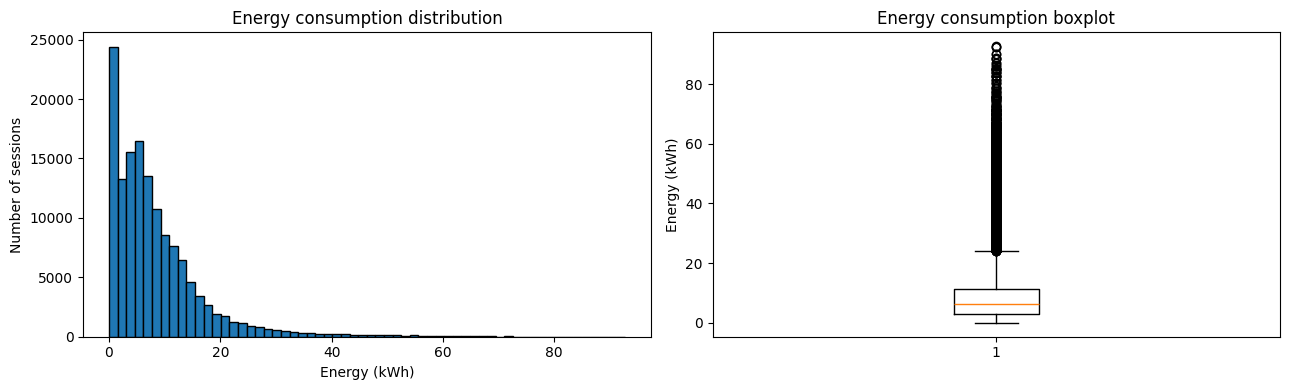

,count,mean,std,min,25%,50%,75%,max
_target_energy_kwh,140320.0,8.450761,8.835758,0.0,2.819,6.224,11.389,92.691
_total_duration_sec,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
_charging_duration_sec,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
_start_hour,140320.0,12.816035,4.051283,0.0,10.000,13.000,16.000,23.000
_start_dow,140320.0,3.042802,1.951615,0.0,1.000,3.000,5.000,6.000
_start_month,140320.0,6.621572,3.321912,1.0,4.000,7.000,9.000,12.000
_idle_ratio,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["_target_energy_kwh"], bins=60, edgecolor="black")
axes[0].set_title("Energy consumption distribution")
axes[0].set_xlabel("Energy (kWh)")
axes[0].set_ylabel("Number of sessions")
axes[1].boxplot(df["_target_energy_kwh"].dropna(), vert=True)
axes[1].set_title("Energy consumption boxplot")
axes[1].set_ylabel("Energy (kWh)")
plt.tight_layout()
plt.show()

display(df[["_target_energy_kwh", "_total_duration_sec", "_charging_duration_sec",
             "_start_hour", "_start_dow", "_start_month", "_idle_ratio"]].describe().T)

## 6. Define two feature sets

**Paper-style features:** total duration, charging duration, start hour, day of week, and month.

**Proposed features:** the same duration predictors, cyclical encodings for hour/day-of-week/month, and idle ratio only when independently available. Cyclical encoding prevents artificial jumps between 23:00 and 00:00 and between adjacent calendar periods.

**Prediction-time caveat:** session duration is only a valid predictor if it is known when the prediction is made (for example, an estimate or completed-session retrospective prediction). If the real goal is to forecast energy before a session starts, future total/charging duration would not be available and must be removed. The paper's setup is closer to session-level estimation than a pure pre-session forecast.

In [6]:
# Core five predictors, matching the paper's described feature categories.
paper_features = [
    "_total_duration_sec",
    "_charging_duration_sec",
    "_start_hour",
    "_start_dow",
    "_start_month",
]

# Cyclical transformations for the proposed model.
df["_hour_sin"] = np.sin(2 * np.pi * df["_start_hour"] / 24)
df["_hour_cos"] = np.cos(2 * np.pi * df["_start_hour"] / 24)
df["_dow_sin"] = np.sin(2 * np.pi * df["_start_dow"] / 7)
df["_dow_cos"] = np.cos(2 * np.pi * df["_start_dow"] / 7)
df["_month_sin"] = np.sin(2 * np.pi * (df["_start_month"] - 1) / 12)
df["_month_cos"] = np.cos(2 * np.pi * (df["_start_month"] - 1) / 12)

proposed_features = [
    "_total_duration_sec",
    "_charging_duration_sec",
    "_hour_sin", "_hour_cos",
    "_dow_sin", "_dow_cos",
    "_month_sin", "_month_cos",
]
if has_separate_durations and df["_idle_ratio"].notna().any():
    proposed_features.append("_idle_ratio")

print("Paper-style features:", paper_features)
print("Proposed features:", proposed_features)
print("Separate duration columns available:", has_separate_durations)

Paper-style features: ['_total_duration_sec', '_charging_duration_sec', '_start_hour', '_start_dow', '_start_month']
Proposed features: ['_total_duration_sec', '_charging_duration_sec', '_hour_sin', '_hour_cos', '_dow_sin', '_dow_cos', '_month_sin', '_month_cos']
Separate duration columns available: True


### Important deployment note: feature availability

The paper-style feature set includes total duration and charging duration. These values may only be known after a charging session has ended. Therefore, these experiments reproduce the paper's feature categories, but they do **not** establish that the model can predict energy before a session starts. Before deployment, define the prediction time and evaluate a separate feature set containing only information available at that time. Do not describe duration-based results as pre-session forecasting unless duration is genuinely available in advance.

## 7. Metrics and model factory

MAE, MSE, RMSE, R², and range-normalised RMSE using the **test-set range**. This makes the NRMSE definition explicit; it is not automatically identical to the paper's value unless the exact same test data and normalisation were used.

Negative predictions are retained for the main metrics because clipping them would hide a model limitation. A separate clipped prediction check is reported for models where physical non-negativity matters.

In [7]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = float(np.sqrt(mse))
    value_range = float(np.max(y_true) - np.min(y_true))
    nrmse = rmse / value_range if value_range > 0 else np.nan
    return {
        "MAE_kWh": mae,
        "MSE_kWh2": mse,
        "RMSE_kWh": rmse,
        "R2": r2_score(y_true, y_pred),
        "NRMSE_test_range": nrmse,
        "Negative_prediction_count": int(np.sum(y_pred < 0)),
    }

def make_models():
    # Imputation is part of each pipeline; it learns medians from training data only.
    return {
        "Dummy median": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DummyRegressor(strategy="median")),
        ]),
        "Random Forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=200, min_samples_leaf=2,
                random_state=SEED, n_jobs=-1
            )),
        ]),
        "Extra Trees": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", ExtraTreesRegressor(
                n_estimators=200, min_samples_leaf=1,
                random_state=SEED, n_jobs=-1
            )),
        ]),
    }

# Published reference metrics from Hussain et al. (2025), reproduced from the paper/Phase 1.
# These are not calculated from your local dataset.
published_reference = pd.DataFrame([
    {"Model": "Extra Trees (published)", "MAE_kWh": 0.5888, "MSE_kWh2": 3.2683,
     "R2": 0.9592, "RMSE_kWh": 1.8078, "NRMSE_test_range": 0.0200},
    {"Model": "XGBoost (published)", "MAE_kWh": 1.8680, "MSE_kWh2": 7.9290,
     "R2": 0.9010, "RMSE_kWh": 2.8159, "NRMSE_test_range": 0.0310},
    {"Model": "Gradient Boosting (published)", "MAE_kWh": 2.0306, "MSE_kWh2": 9.3121,
     "R2": 0.8838, "RMSE_kWh": 3.0520, "NRMSE_test_range": 0.0330},
])
display(published_reference)

,Model,MAE_kWh,MSE_kWh2,R2,RMSE_kWh,NRMSE_test_range
0,Extra Trees (published),0.5888,3.2683,0.9592,1.8078,0.020
1,XGBoost (published),1.8680,7.9290,0.9010,2.8159,0.031
2,Gradient Boosting (published),2.0306,9.3121,0.8838,3.0520,0.033


## 8. Experiment A — random 80/20 split

This is a **comparability experiment**, approximating the paper's stated 80% training / 20% testing setup. We use a fixed random seed for reproducibility. Because rows from nearby dates can occur in both sets, do not interpret this as the strongest evidence of future forecasting performance.

In [8]:
X_random_paper = df[paper_features].copy()
y_random = df["_target_energy_kwh"].copy()
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_random_paper, y_random, test_size=0.20, random_state=SEED
)

random_results = []
random_predictions = {}
for name, model in make_models().items():
    model.fit(X_train_r, y_train_r)
    pred = model.predict(X_test_r)
    random_predictions[name] = pred
    random_results.append({"Split": "Random 80/20", "Feature_Set": "Paper-style", "Model": name,
                           **regression_metrics(y_test_r, pred)})

random_results_df = pd.DataFrame(random_results).sort_values("RMSE_kWh")
display(random_results_df)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_

,Split,Feature_Set,Model,MAE_kWh,MSE_kWh2,RMSE_kWh,R2,NRMSE_test_range,Negative_prediction_count
2,Random 80/20,Paper-style,Extra Trees,5.905346,75.169533,8.670037,0.052411,0.096327,0
1,Random 80/20,Paper-style,Random Forest,5.922459,75.385682,8.682493,0.049686,0.096466,0
0,Random 80/20,Paper-style,Dummy median,5.740904,84.354348,9.184462,-0.063373,0.102043,0


## 9. Experiment B — chronological hold-out (timestamp groups kept intact)

The final test period is selected by timestamp, not by cutting through the sorted rows. Records with the same start timestamp are kept in the same partition so a timestamp cannot appear in both training and test data. Because timestamps may have different numbers of records, the resulting row split may be close to, but not exactly, 80/20.

This is the more appropriate evaluation for a future-period prediction scenario. It does not by itself eliminate every possible dependency (for example, repeated vehicles or stations), but it avoids splitting identical start times across the boundary.

In [9]:
# Choose the timestamp boundary whose cumulative row count is closest to 80%.
time_counts = df.groupby("_start_dt", sort=True).size()
if len(time_counts) < 2:
    raise ValueError("At least two distinct start timestamps are required for a chronological split.")

target_train_rows = 0.80 * len(df)
cumulative_rows = time_counts.cumsum().to_numpy()
# Candidate boundaries must leave at least one timestamp group on each side.
candidate_positions = np.arange(1, len(time_counts))
split_pos = int(candidate_positions[np.argmin(np.abs(cumulative_rows[candidate_positions - 1] - target_train_rows))])
cutoff_time = time_counts.index[split_pos]

train_time = df.loc[df["_start_dt"] < cutoff_time].copy().reset_index(drop=True)
test_time = df.loc[df["_start_dt"] >= cutoff_time].copy().reset_index(drop=True)

if len(train_time) == 0 or len(test_time) == 0:
    raise ValueError("Chronological split produced an empty partition.")

X_train_t = train_time[paper_features].copy()
y_train_t = train_time["_target_energy_kwh"].copy()
X_test_t = test_time[paper_features].copy()
y_test_t = test_time["_target_energy_kwh"].copy()

temporal_results = []
temporal_predictions = {}
temporal_models = {}
for name, model in make_models().items():
    model.fit(X_train_t, y_train_t)
    pred = model.predict(X_test_t)
    temporal_models[name] = model
    temporal_predictions[name] = pred
    temporal_results.append({"Split": "Chronological timestamp-grouped hold-out",
                             "Feature_Set": "Paper-style", "Model": name,
                             **regression_metrics(y_test_t, pred)})

temporal_results_df = pd.DataFrame(temporal_results).sort_values("RMSE_kWh")
display(temporal_results_df)
print("Train rows:", len(train_time), f"({len(train_time)/len(df):.2%})")
print("Test rows:", len(test_time), f"({len(test_time)/len(df):.2%})")
print("Train period:", train_time["_start_dt"].min(), "to", train_time["_start_dt"].max())
print("Test period: ", test_time["_start_dt"].min(), "to", test_time["_start_dt"].max())
print("Timestamp groups shared across train/test:",
      len(set(train_time["_start_dt"]).intersection(set(test_time["_start_dt"]))))


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_

,Split,Feature_Set,Model,MAE_kWh,MSE_kWh2,RMSE_kWh,R2,NRMSE_test_range,Negative_prediction_count
1,Chronological timestamp-grouped hold-out,Paper-style,Random Forest,6.741623,98.171472,9.908152,-0.003618,0.106894,0
2,Chronological timestamp-grouped hold-out,Paper-style,Extra Trees,6.750991,98.661950,9.932872,-0.008632,0.107161,0
0,Chronological timestamp-grouped hold-out,Paper-style,Dummy median,6.421790,104.035835,10.199796,-0.063570,0.110041,0


Train rows: 112256 (80.00%)
Test rows: 28064 (20.00%)
Train period: 2018-01-01 17:49:00 to 2023-03-03 08:01:00
Test period:  2023-03-03 08:12:00 to 2023-11-30 23:27:00
Timestamp groups shared across train/test: 0


## 10. Experiment C — proposed feature engineering and log-target test

We compare the best-performing tree model on the chronological hold-out using:
- the paper-style features;
- the proposed cyclical time encodings and optional idle ratio;
- the proposed feature set with `log1p(y)` target transformation, with predictions transformed back using `expm1`.

The log transform is an experiment, not an assumption that the target is log-normal. Scores are calculated on the original kWh scale. Predictions from the transformed model are clipped at zero only for this log-target variant, because `expm1` can theoretically produce negative values for negative transformed predictions.

In [10]:
improved_results = []
improved_predictions = {}

candidate_specs = [
    ("Extra Trees / paper-style", paper_features, False),
    ("Extra Trees / proposed features", proposed_features, False),
    ("Extra Trees / proposed + log1p target", proposed_features, True),
]

for label, features, use_log_target in candidate_specs:
    base = ExtraTreesRegressor(
        n_estimators=200, min_samples_leaf=1,
        random_state=SEED, n_jobs=-1
    )
    if use_log_target:
        estimator = TransformedTargetRegressor(
            regressor=Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("model", base),
            ]),
            func=np.log1p,
            inverse_func=np.expm1,
            check_inverse=True,
        )
    else:
        estimator = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", base),
        ])

    estimator.fit(train_time[features], y_train_t)
    pred = estimator.predict(test_time[features])
    if use_log_target:
        pred = np.maximum(pred, 0)
    improved_predictions[label] = pred
    improved_results.append({
        "Split": "Chronological 80/20",
        "Feature_Set": label,
        "Model": "Extra Trees",
        **regression_metrics(y_test_t, pred)
    })

improved_results_df = pd.DataFrame(improved_results).sort_values("RMSE_kWh")
display(improved_results_df)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_

,Split,Feature_Set,Model,MAE_kWh,MSE_kWh2,RMSE_kWh,R2,NRMSE_test_range,Negative_prediction_count
0,Chronological 80/20,Extra Trees / paper-style,Extra Trees,6.750991,98.661950,9.932872,-0.008632,0.107161,0
1,Chronological 80/20,Extra Trees / proposed features,Extra Trees,6.754062,98.768391,9.938229,-0.009720,0.107219,0
2,Chronological 80/20,Extra Trees / proposed + log1p target,Extra Trees,6.478855,106.528885,10.321283,-0.089056,0.111352,0


## 11. Consolidated comparison and published results

Published figures are useful context, but they are **not a direct head-to-head comparison** unless the exact dataset version, cleaned rows, feature engineering, split, seed, and hyperparameters match. The paper reports Extra Trees at MAE 0.5888 kWh, RMSE 1.8078 kWh, and R² 0.9592. If your metrics differ, discuss plausible causes rather than changing the experiment to force a match.

In [17]:
all_local_results = pd.concat([random_results_df, temporal_results_df, improved_results_df], ignore_index=True)
display(all_local_results.sort_values(["Split", "RMSE_kWh"]))

print("Published reference — Extra Trees:")
display(published_reference.loc[published_reference["Model"] == "Extra Trees (published)"])
print(
    "Comparison caution: the published score is reported for the authors' experimental setup; "
    "your random and chronological splits are locally computed and may not be directly comparable."
)

,Split,Feature_Set,Model,MAE_kWh,MSE_kWh2,RMSE_kWh,R2,NRMSE_test_range,Negative_prediction_count
6,Chronological 80/20,Extra Trees / paper-style,Extra Trees,6.750991,98.661950,9.932872,-0.008632,0.107161,0
7,Chronological 80/20,Extra Trees / proposed features,Extra Trees,6.754062,98.768391,9.938229,-0.009720,0.107219,0
8,Chronological 80/20,Extra Trees / proposed + log1p target,Extra Trees,6.478855,106.528885,10.321283,-0.089056,0.111352,0
3,Chronological timestamp-grouped hold-out,Paper-style,Random Forest,6.741623,98.171472,9.908152,-0.003618,0.106894,0
4,Chronological timestamp-grouped hold-out,Paper-style,Extra Trees,6.750991,98.661950,9.932872,-0.008632,0.107161,0
5,Chronological timestamp-grouped hold-out,Paper-style,Dummy median,6.421790,104.035835,10.199796,-0.063570,0.110041,0
0,Random 80/20,Paper-style,Extra Trees,5.905346,75.169533,8.670037,0.052411,0.096327,0
1,Random 80/20,Paper-style,Random Forest,5.922459,75.385682,8.682493,0.049686,0.096466,0
2,Random 80/20,Paper-style,Dummy median,5.740904,84.354348,9.184462,-0.063373,0.102043,0


Published reference — Extra Trees:


,Model,MAE_kWh,MSE_kWh2,R2,RMSE_kWh,NRMSE_test_range
0,Extra Trees (published),0.5888,3.2683,0.9592,1.8078,0.02


Comparison caution: the published score is reported for the authors' experimental setup; your random and chronological splits are locally computed and may not be directly comparable.


## 12. Diagnostic plots for the pre-specified paper-style Extra Trees model

To avoid choosing a model based on the final test-set scores and then presenting that same test set as an unbiased diagnostic, these plots use the paper-style Extra Trees candidate chosen in advance. Alternative feature/target variants are still compared in the results table, but the final test set should not be repeatedly used for tuning.

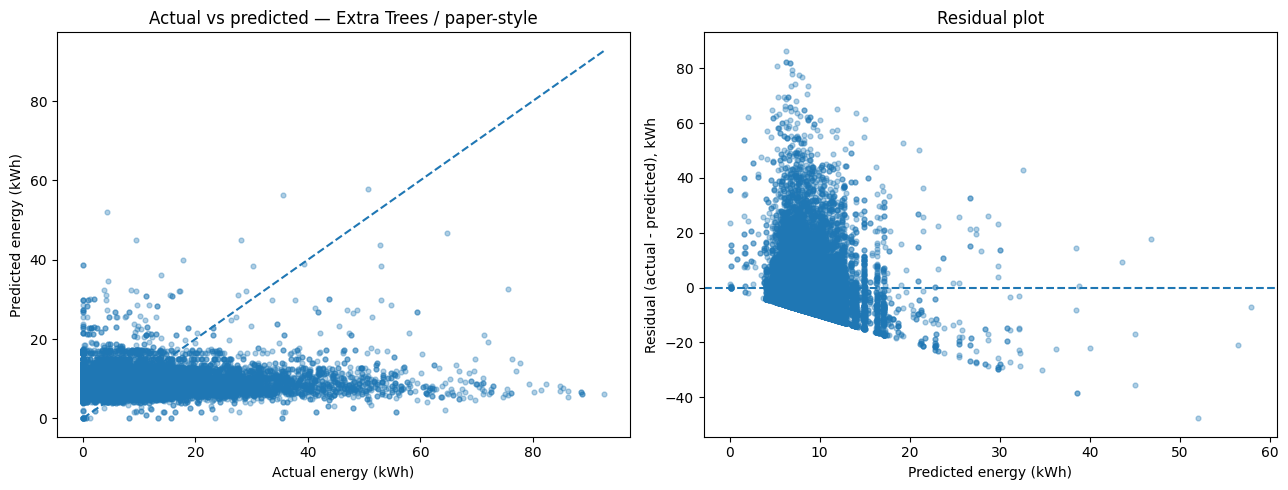

Pre-specified diagnostic candidate: Extra Trees / paper-style


,actual_kWh,predicted_kWh,residual_kWh
0,7.558,14.96875,-7.41075
1,7.558,14.96875,-7.41075
2,19.186,14.96875,4.21725
3,19.186,14.96875,4.21725
4,2.258,14.96875,-12.71075
5,2.258,14.96875,-12.71075
6,10.368,14.96875,-4.60075
7,10.368,14.96875,-4.60075
8,12.420,14.96875,-2.54875
9,12.420,14.96875,-2.54875


In [12]:
diagnostic_label = "Extra Trees / paper-style"
best_label = diagnostic_label
best_pred = improved_predictions[diagnostic_label]
residuals = y_test_t.to_numpy() - best_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test_t, best_pred, alpha=0.35, s=12)
low = min(float(y_test_t.min()), float(np.min(best_pred)))
high = max(float(y_test_t.max()), float(np.max(best_pred)))
axes[0].plot([low, high], [low, high], linestyle="--")
axes[0].set_xlabel("Actual energy (kWh)")
axes[0].set_ylabel("Predicted energy (kWh)")
axes[0].set_title(f"Actual vs predicted — {best_label}")

axes[1].scatter(best_pred, residuals, alpha=0.35, s=12)
axes[1].axhline(0, linestyle="--")
axes[1].set_xlabel("Predicted energy (kWh)")
axes[1].set_ylabel("Residual (actual - predicted), kWh")
axes[1].set_title("Residual plot")
plt.tight_layout()
plt.show()

print("Pre-specified diagnostic candidate:", best_label)
display(pd.DataFrame({"actual_kWh": y_test_t.to_numpy(), "predicted_kWh": best_pred, "residual_kWh": residuals}).head(10))

## 13. Error analysis by energy range

Large charging sessions may be harder to estimate and can dominate RMSE. The following table compares errors across actual-energy quartile groups. It is diagnostic only; quartile boundaries are derived from the test targets, not used for model training.

In [13]:
error_df = pd.DataFrame({
    "actual_kWh": y_test_t.to_numpy(),
    "predicted_kWh": best_pred,
})
error_df["absolute_error_kWh"] = np.abs(error_df["actual_kWh"] - error_df["predicted_kWh"])
try:
    error_df["actual_energy_group"] = pd.qcut(
        error_df["actual_kWh"], q=4, duplicates="drop"
    )
    error_summary = error_df.groupby("actual_energy_group", observed=False).agg(
        sessions=("actual_kWh", "size"),
        mean_actual_kWh=("actual_kWh", "mean"),
        MAE_kWh=("absolute_error_kWh", "mean"),
        max_absolute_error_kWh=("absolute_error_kWh", "max"),
    ).reset_index()
    display(error_summary)
except ValueError as exc:
    print("Could not form energy quartiles:", exc)

,actual_energy_group,sessions,mean_actual_kWh,MAE_kWh,max_absolute_error_kWh
0,"(-0.001, 2.255]",7018,0.418000,7.755233,38.595500
1,"(2.255, 6.028]",7014,4.258710,3.992309,47.749000
2,"(6.028, 11.848]",7017,8.587209,2.221630,35.488000
3,"(11.848, 92.691]",7015,21.763607,13.035262,86.437128


## 14. Optional expanding-window cross-validation on the training period

This evaluates the proposed-feature Extra Trees model on multiple forward-moving folds within the training period. The final chronological test period is not used for CV. Folds are built from unique timestamps, so identical start times are kept together.

In [14]:
RUN_TEMPORAL_CV = True

if RUN_TEMPORAL_CV:
    cv_frame = train_time.reset_index(drop=True)
    cv_features = proposed_features
    X_cv = cv_frame[cv_features].copy()
    y_cv = cv_frame["_target_energy_kwh"].copy()
    unique_times = cv_frame["_start_dt"].drop_duplicates().to_numpy()
    n_splits = 4
    if len(unique_times) < n_splits + 1:
        n_splits = max(2, len(unique_times) - 1)
    if n_splits < 2:
        raise ValueError("Not enough unique timestamps for temporal cross-validation.")

    splitter = TimeSeriesSplit(n_splits=n_splits)
    grouped_splits = []
    for train_time_idx, valid_time_idx in splitter.split(unique_times):
        train_times = unique_times[train_time_idx]
        valid_times = unique_times[valid_time_idx]
        train_idx = np.flatnonzero(cv_frame["_start_dt"].isin(train_times).to_numpy())
        valid_idx = np.flatnonzero(cv_frame["_start_dt"].isin(valid_times).to_numpy())
        grouped_splits.append((train_idx, valid_idx))

    cv_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesRegressor(
            n_estimators=120, min_samples_leaf=1,
            random_state=SEED, n_jobs=-1
        )),
    ])
    cv_scores = cross_validate(
        cv_model, X_cv, y_cv, cv=grouped_splits,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2",
        },
        n_jobs=1, return_train_score=False,
    )
    cv_summary = pd.DataFrame({
        "MAE_kWh": -cv_scores["test_MAE"],
        "RMSE_kWh": -cv_scores["test_RMSE"],
        "R2": cv_scores["test_R2"],
    })
    display(cv_summary)
    display(cv_summary.agg(["mean", "std"]).T.rename(columns={"mean":"fold_mean", "std":"fold_std"}))
else:
    print("Temporal cross-validation skipped by configuration.")


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_

,MAE_kWh,RMSE_kWh,R2
0,5.607683,8.191080,-0.164593
1,5.699267,8.436508,-0.057150
2,6.195518,9.193122,-0.013396
3,6.759004,10.345442,-0.025486


,fold_mean,fold_std
MAE_kWh,6.065368,0.529646
RMSE_kWh,9.041538,0.968243
R2,-0.065156,0.068810


## 15. Reproducibility checks and sanity assertions

These checks catch common implementation mistakes:
- the cleaned target is finite and non-negative;
- the target is not included in either feature list;
- the paper's GHG/gasoline savings fields are not included;
- chronological training ends before chronological testing begins;
- metric values are finite when the test set has non-zero target range;
- repeated fixed-seed fitting returns identical predictions on a small deterministic sample.

A deterministic smoke test does not prove that a model generalises well; it checks implementation repeatability.

In [15]:
assert df["_target_energy_kwh"].notna().all(), "Missing targets remain after cleaning."
assert (df["_target_energy_kwh"] >= 0).all(), "Negative target values remain."
assert target_col not in paper_features and target_col not in proposed_features
assert "_target_energy_kwh" not in paper_features + proposed_features
assert train_time["_start_dt"].max() <= test_time["_start_dt"].min(), "Chronological split is not ordered."
assert len(X_train_t) == len(y_train_t) and len(X_test_t) == len(y_test_t)

# Confirm that target-derived environmental fields are not predictors.
for f in paper_features + proposed_features:
    low_name = str(f).lower()
    assert "ghg" not in low_name and "gasoline" not in low_name and "savings" not in low_name

smoke_n = min(500, len(X_train_t))
smoke_X = X_train_t.iloc[:smoke_n]
smoke_y = y_train_t.iloc[:smoke_n]
if smoke_n >= 10:
    m1 = ExtraTreesRegressor(n_estimators=20, random_state=SEED, n_jobs=1)
    m2 = ExtraTreesRegressor(n_estimators=20, random_state=SEED, n_jobs=1)
    m1.fit(SimpleImputer(strategy="median").fit_transform(smoke_X), smoke_y)
    m2.fit(SimpleImputer(strategy="median").fit_transform(smoke_X), smoke_y)
    p1 = m1.predict(SimpleImputer(strategy="median").fit(smoke_X).transform(smoke_X))
    p2 = m2.predict(SimpleImputer(strategy="median").fit(smoke_X).transform(smoke_X))
    assert np.allclose(p1, p2), "Fixed-seed repeatability check failed."
    print("Repeatability smoke test passed.")
else:
    print("Dataset is too small for the optional repeatability smoke test.")

print("All data/feature/split sanity assertions passed.")

Repeatability smoke test passed.
All data/feature/split sanity assertions passed.


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_sec']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['_total_duration_sec' '_charging_duration_

In [16]:
results_path = Path("phase2_model_comparison_results.csv")
predictions_path = Path("phase2_chronological_test_predictions.csv")

all_local_results.to_csv(results_path, index=False)

export_predictions = pd.DataFrame({
    "source_row_id": test_time["_source_row_id"].to_numpy(),
    "start_timestamp": test_time["_start_dt"].to_numpy(),
    "actual_energy_kWh": y_test_t.to_numpy(),
})
for label, pred in improved_predictions.items():
    export_predictions[label] = pred
export_predictions.to_csv(predictions_path, index=False)

print("Saved:", results_path.resolve())
print("Saved:", predictions_path.resolve())
print("Prediction rows exported:", len(export_predictions))
print("Exact duplicate raw rows were audited above but not automatically removed.")
display(all_local_results.sort_values(["Split", "RMSE_kWh"]))


Saved: /content/phase2_model_comparison_results.csv
Saved: /content/phase2_chronological_test_predictions.csv
Prediction rows exported: 28064
Exact duplicate raw rows were audited above but not automatically removed.


,Split,Feature_Set,Model,MAE_kWh,MSE_kWh2,RMSE_kWh,R2,NRMSE_test_range,Negative_prediction_count
6,Chronological 80/20,Extra Trees / paper-style,Extra Trees,6.750991,98.661950,9.932872,-0.008632,0.107161,0
7,Chronological 80/20,Extra Trees / proposed features,Extra Trees,6.754062,98.768391,9.938229,-0.009720,0.107219,0
8,Chronological 80/20,Extra Trees / proposed + log1p target,Extra Trees,6.478855,106.528885,10.321283,-0.089056,0.111352,0
3,Chronological timestamp-grouped hold-out,Paper-style,Random Forest,6.741623,98.171472,9.908152,-0.003618,0.106894,0
4,Chronological timestamp-grouped hold-out,Paper-style,Extra Trees,6.750991,98.661950,9.932872,-0.008632,0.107161,0
5,Chronological timestamp-grouped hold-out,Paper-style,Dummy median,6.421790,104.035835,10.199796,-0.063570,0.110041,0
0,Random 80/20,Paper-style,Extra Trees,5.905346,75.169533,8.670037,0.052411,0.096327,0
1,Random 80/20,Paper-style,Random Forest,5.922459,75.385682,8.682493,0.049686,0.096466,0
2,Random 80/20,Paper-style,Dummy median,5.740904,84.354348,9.184462,-0.063373,0.102043,0


### Reference
Hussain, I., Ching, K. B., Uttraphan, C., Tay, K. G., & Noor, A. (2025). *Evaluating machine learning algorithms for energy consumption prediction in electric vehicles: A comparative study*. Scientific Reports, 15, Article 16124. https://doi.org/10.1038/s41598-025-94946-7